# Heart Disease Prediction

## Problem description

Heart disease is still one of the main causes of death, and many people who have it are only checked after symptoms are already serious. Clinics already collect a small set of routine measurements during a visit: age, sex, chest-pain type, resting blood pressure, cholesterol, fasting blood sugar, resting ECG, maximum heart rate, exercise-induced angina, ST depression (`Oldpeak`), and the slope of the ST segment. Reading those numbers one by one is slow, and a busy screening program can miss people who should be sent on for a proper cardiac workup.

This project builds a model that estimates whether a patient has heart disease from those measurements. The output is a probability, not a diagnosis. A clinic or screening desk would call a small web service with the 11 measurements and get back a score. A high score means "refer this person for follow-up" (repeat ECG, cardiologist, further tests). A low score means the routine visit can continue as usual. A doctor still makes the medical decision. The model only ranks who should be seen sooner.

The data is the [Heart Failure Prediction dataset](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction) published by fedesoriano. It combines five public heart-disease collections (Cleveland, Hungarian, Switzerland, Long Beach VA, and Statlog) into 918 patient records and 11 shared clinical features. The target is `HeartDisease`: `1` if the patient has heart disease, `0` otherwise. The two classes are close in size, so the main metric is ROC AUC, with accuracy reported alongside it.

The dataset is large enough for a real train/validation split, small enough to train on a laptop, and every feature is something a clinic can type into a form. That makes the model straightforward to serve later as a `POST /predict` endpoint.


## Data preparation

Load the CSV, make the column names and text values uniform, and turn impossible zeros into missing values.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv('heart.csv')
df.head()


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
df.dtypes


Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.head()


,age,sex,chestpaintype,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease
0,40,m,ata,140,289,0,normal,172,n,0.0,up,0
1,49,f,nap,160,180,0,normal,156,n,1.0,flat,1
2,37,m,ata,130,283,0,st,98,n,0.0,up,0
3,48,f,asy,138,214,0,normal,108,y,1.5,flat,1
4,54,m,nap,150,195,0,normal,122,n,0.0,up,0


There are no `NaN` values in the file. `cholesterol` and `restingbp` use `0` for a measurement that was not taken. A cholesterol or a resting blood pressure of 0 is impossible, so those zeros are missing. Zeros in `oldpeak`, `fastingbs`, and `heartdisease` are real values.


In [5]:
df.isnull().sum()


age               0
sex               0
chestpaintype     0
restingbp         0
cholesterol       0
fastingbs         0
restingecg        0
maxhr             0
exerciseangina    0
oldpeak           0
st_slope          0
heartdisease      0
dtype: int64

In [6]:
numeric = df.select_dtypes(include='number').columns
(df[numeric] == 0).sum()


age               0
restingbp         1
cholesterol     172
fastingbs       704
maxhr             0
oldpeak         368
heartdisease    410
dtype: int64

In [7]:
cols = ['restingbp', 'cholesterol']
df[cols] = df[cols].replace(0, np.nan)

df[cols].isnull().sum()


restingbp        1
cholesterol    172
dtype: int64

## Train, validation, and test split

60% train, 20% validation, 20% test. `random_state=1` keeps the same rows in each set on every run. `df_full_train` keeps the target for EDA. The target is removed from the three modeling sets.


In [8]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

len(df_train), len(df_val), len(df_test)


(550, 184, 184)

In [9]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

y_train = df_train.heartdisease.values
y_val = df_val.heartdisease.values
y_test = df_test.heartdisease.values

del df_train['heartdisease']
del df_val['heartdisease']
del df_test['heartdisease']


## EDA

EDA uses `df_full_train`, which is the train and validation rows together.


In [10]:
df_full_train.isnull().sum()


age                 0
sex                 0
chestpaintype       0
restingbp           0
cholesterol       142
fastingbs           0
restingecg          0
maxhr               0
exerciseangina      0
oldpeak             0
st_slope            0
heartdisease        0
dtype: int64

In [21]:
df_full_train.heartdisease.value_counts(normalize=True)


heartdisease
1    0.542234
0    0.457766
Name: proportion, dtype: float64

In [12]:
global_rate = df_full_train.heartdisease.mean()
global_rate


np.float64(0.5422343324250681)

`fastingbs` is stored as 0/1, so it is treated as a category. The other numeric columns are `age`, `restingbp`, `cholesterol`, `maxhr`, and `oldpeak`.


In [13]:
numerical = ['age', 'restingbp', 'cholesterol', 'maxhr', 'oldpeak']

categorical = [
    'sex',
    'chestpaintype',
    'fastingbs',
    'restingecg',
    'exerciseangina',
    'st_slope',
]


In [14]:
df_full_train[numerical].describe()


,age,restingbp,cholesterol,maxhr,oldpeak
count,734.000000,734.000000,592.000000,734.000000,734.000000
mean,53.392371,132.538147,244.569257,137.245232,0.845777
std,9.316842,17.778017,61.135521,25.207999,1.043516
min,28.000000,80.000000,85.000000,60.000000,-2.600000
25%,47.000000,120.000000,207.000000,120.000000,0.000000
50%,54.000000,130.000000,237.500000,139.500000,0.500000
75%,60.000000,140.000000,275.000000,156.000000,1.500000
max,77.000000,200.000000,603.000000,202.000000,6.200000


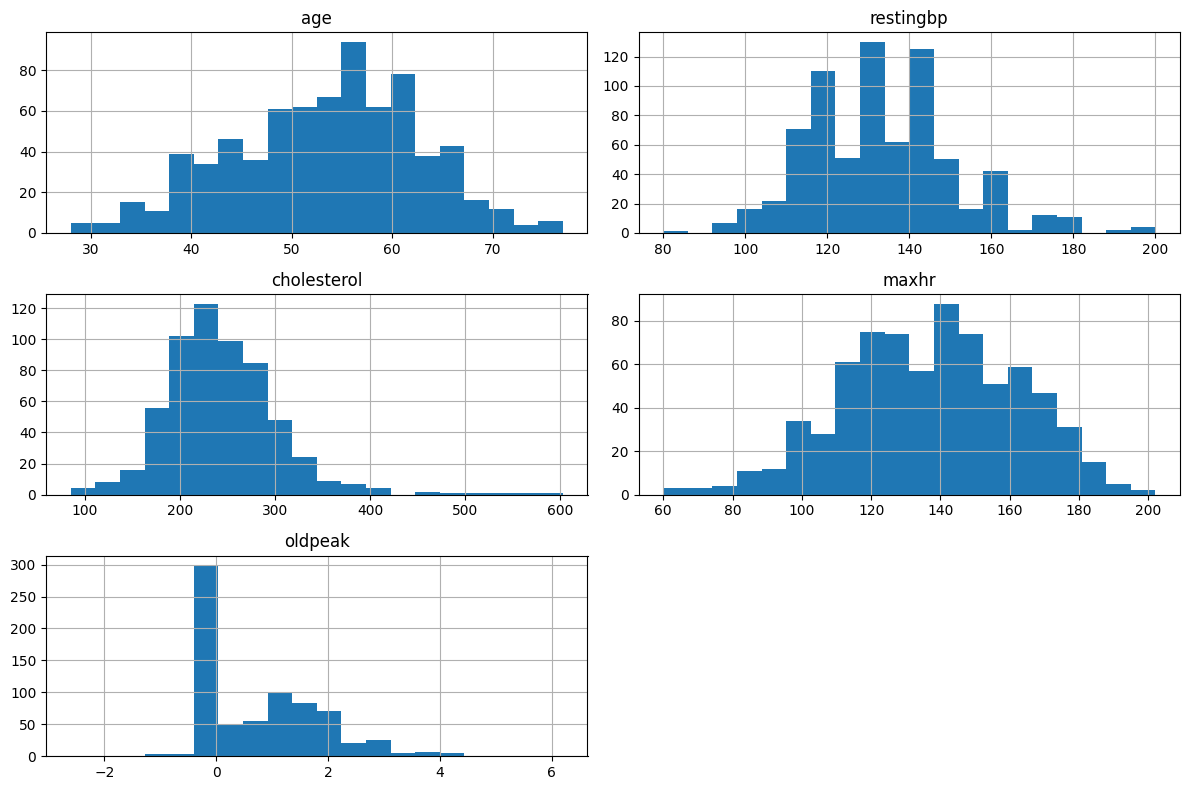

In [15]:
df_full_train[numerical].hist(bins=20, figsize=(12, 8))
plt.tight_layout()


In [16]:
for col in categorical:
    print(col)
    print(df_full_train[col].value_counts())
    print()


sex
sex
m    577
f    157
Name: count, dtype: int64

chestpaintype
chestpaintype
asy    394
nap    168
ata    133
ta      39
Name: count, dtype: int64

fastingbs
fastingbs
0    565
1    169
Name: count, dtype: int64

restingecg
restingecg
normal    436
lvh       152
st        146
Name: count, dtype: int64

exerciseangina
exerciseangina
n    444
y    290
Name: count, dtype: int64

st_slope
st_slope
flat    373
up      322
down     39
Name: count, dtype: int64



In [17]:
df_full_train.groupby(df_full_train.cholesterol.isnull()).heartdisease.agg(['mean', 'count'])


,mean,count
cholesterol,,
False,0.456081,592
True,0.901408,142


## Feature importance

For each category, `mean` is the heart-disease rate inside that group. `risk` divides that rate by the overall rate. A risk above 1 means the group has heart disease more often than the dataset as a whole.


In [18]:
for col in categorical:
    df_group = df_full_train.groupby(col).heartdisease.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_rate
    df_group['risk'] = df_group['mean'] / global_rate
    print(col)
    print(df_group)
    print()


sex
         mean  count      diff      risk
sex                                     
f    0.254777    157 -0.287457  0.469865
m    0.620451    577  0.078216  1.144248

chestpaintype
                   mean  count      diff      risk
chestpaintype                                     
asy            0.774112    394  0.231877  1.427633
ata            0.120301    133 -0.421934  0.221861
nap            0.345238    168 -0.196996  0.636695
ta             0.487179     39 -0.055055  0.898467

fastingbs
               mean  count      diff      risk
fastingbs                                     
0          0.476106    565 -0.066128  0.878045
1          0.763314    169  0.221079  1.407719

restingecg
                mean  count      diff      risk
restingecg                                     
lvh         0.519737    152 -0.022497  0.958510
normal      0.511468    436 -0.030766  0.943260
st          0.657534    146  0.115300  1.212639

exerciseangina
                    mean  count      diff   

The overall disease rate in the full train set is about 54%.

The groups with the higher rates are exercise-induced angina (`y`, risk about 1.55), a flat ST slope (`flat`, about 1.49), asymptomatic chest pain (`asy`, about 1.43), and fasting blood sugar above 120 (`fastingbs` of 1, about 1.41). An upsloping ST segment (`up`, about 0.39) and atypical angina (`ata`, about 0.22) have much lower rates. `restingecg` stays near a risk of 1, so it separates the classes less than the others.

Missing `cholesterol` is also informative. Those 142 rows have a disease rate of about 90%, against about 46% where cholesterol was measured.


## Fill missing values

This happens after EDA and before one-hot encoding. The median is computed on `df_train` only, then applied to the validation and test sets.


In [19]:
for col in ['restingbp', 'cholesterol']:
    median = df_train[col].median()
    df_train[col] = df_train[col].fillna(median)
    df_val[col] = df_val[col].fillna(median)
    df_test[col] = df_test[col].fillna(median)

df_train[cols].isnull().sum()


restingbp      0
cholesterol    0
dtype: int64

## One hot encoding

In [ ]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)
train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)


val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [36]:
pd.DataFrame(X_train[:5], columns=dv.get_feature_names_out()).T

,0,1,2,3,4
age,42.0,38.0,57.0,52.0,54.0
chestpaintype=asy,0.0,1.0,1.0,0.0,0.0
chestpaintype=ata,0.0,0.0,0.0,0.0,1.0
chestpaintype=nap,1.0,0.0,0.0,1.0,0.0
chestpaintype=ta,0.0,0.0,0.0,0.0,0.0
cholesterol,240.0,236.0,354.0,236.0,208.0
exerciseangina=n,1.0,1.0,0.0,1.0,1.0
exerciseangina=y,0.0,0.0,1.0,0.0,0.0
fastingbs,1.0,1.0,0.0,0.0,0.0
maxhr,194.0,166.0,163.0,180.0,142.0


## 1st model: logistic regression

In [31]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='lbfgs')
model.fit(X_train, y_train)

/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [32]:
model.intercept_[0]

np.float64(-0.06819281937332866)

In [33]:
model.coef_[0].round(3)

array([ 0.004,  1.266, -0.905, -0.367, -0.063,  0.002, -0.367,  0.298,
        1.131, -0.013,  0.4  ,  0.002, -0.275,  0.013,  0.193, -0.593,
        0.524,  0.004,  1.018, -1.092])

In [42]:
from sklearn.metrics import roc_auc_score, accuracy_score

y_pred_train = model.predict_proba(X_train)[:, 1]
y_pred = model.predict_proba(X_val)[:, 1]

print('train auc', roc_auc_score(y_train, y_pred_train))
print('val auc', roc_auc_score(y_val, y_pred))
print('train acc', accuracy_score(y_train, y_pred_train >= 0.5))
print('val acc', accuracy_score(y_val, y_pred >= 0.5))

train auc 0.9259200000000001
val auc 0.9015187470336973
train acc 0.8545454545454545
val acc 0.8260869565217391


/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/tom/.pyenv/versions/3.10.13/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


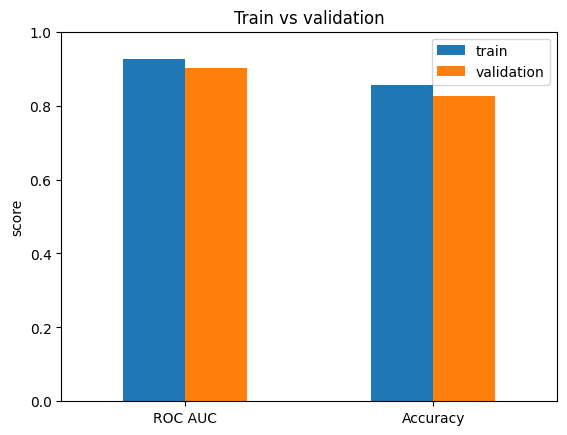

In [43]:
scores = pd.DataFrame({
    'train': [
        roc_auc_score(y_train, y_pred_train),
        accuracy_score(y_train, y_pred_train >= 0.5),
    ],
    'validation': [
        roc_auc_score(y_val, y_pred),
        accuracy_score(y_val, y_pred >= 0.5),
    ],
}, index=['ROC AUC', 'Accuracy'])

scores.plot.bar(ylim=(0, 1), rot=0)
plt.ylabel('score')
plt.title('Train vs validation')
plt.show()

## 2nd model random forest


In [51]:
from sklearn.ensemble import RandomForestClassifier

scores = []

for n in range(10, 501, 10):
    rf = RandomForestClassifier(n_estimators=n, random_state=1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append((n, auc))

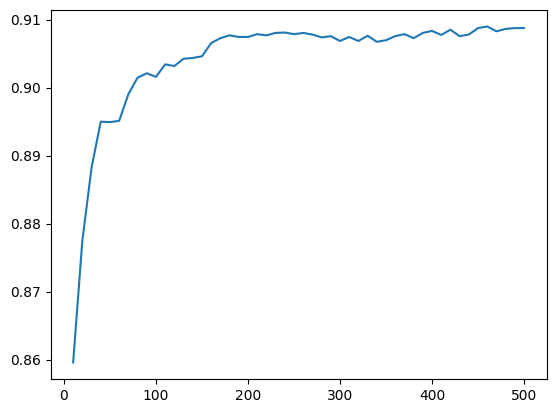

In [52]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])
plt.plot(df_scores.n_estimators, df_scores.auc)

Tuning max_depth

In [55]:
scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))
print(scores)

[(5, 10, 0.8834242999525392), (5, 20, 0.8979591836734694), (5, 30, 0.900094921689606), (5, 40, 0.8977218794494543), (5, 50, 0.896298054105363), (5, 60, 0.8996203132415758), (5, 70, 0.9021120075937352), (5, 80, 0.8993830090175605), (5, 90, 0.8998576174655908), (5, 100, 0.9005695301376364), (5, 110, 0.9002135738016137), (5, 120, 0.8995016611295681), (5, 130, 0.8995016611295682), (5, 140, 0.8991457047935454), (5, 150, 0.8995016611295681), (5, 160, 0.8987897484575225), (5, 170, 0.8990270526815377), (5, 180, 0.8989084005695301), (5, 190, 0.8991457047935453), (5, 200, 0.8979591836734693), (10, 10, 0.8742287612719506), (10, 20, 0.8926791646891316), (10, 30, 0.8960014238253441), (10, 40, 0.9015187470336973), (10, 50, 0.9026459420977692), (10, 60, 0.9035358329378264), (10, 70, 0.9043663977218794), (10, 80, 0.9079259610821072), (10, 90, 0.9091124822021831), (10, 100, 0.9093497864261983), (10, 110, 0.9092311343141908), (10, 120, 0.908875177978168), (10, 130, 0.9091124822021831), (10, 140, 0.90958

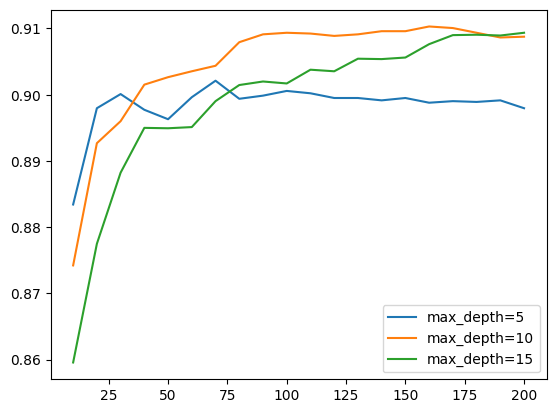

In [54]:
columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.legend()

## Tuning min_samples_leaf

In [57]:
scores = []
max_depth = 10
for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

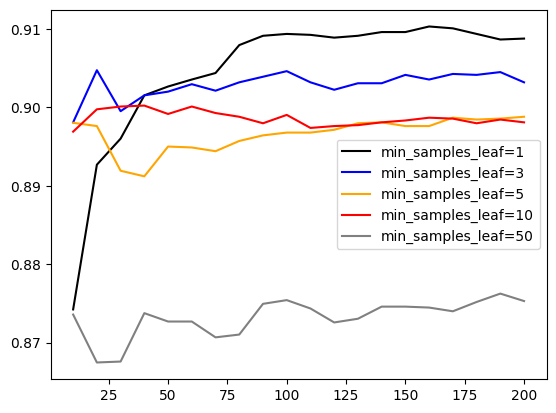

In [58]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s)

plt.legend()

In [65]:
rf = RandomForestClassifier(n_estimators=200,
                            max_depth=10,
                            min_samples_leaf=1,
                            random_state=1)
rf.fit(X_train, y_train)
y_pred = rf.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.9087565258661604

The tuned random forest reaches a validation ROC AUC of **0.909** with `n_estimators=200`, `max_depth=10`, and `min_samples_leaf=1`. Logistic regression reached **0.902** on the same validation patients, so the random forest is the model to keep.

Next: refit this forest on `df_full_train`, then score it once on the test set.


## Final model

The validation comparison selected the random forest. Refit it on the `df_full_train` created above. That frame still has `heartdisease` and the missing cholesterol values. The earlier `df_test` was already filled and its target was removed, so the test rows are taken again from `df` with the same `random_state=1`. The medians and the one-hot encoder are fit on `df_full_train` only.


In [68]:
df_full = df_full_train.copy()
_, df_test_final = train_test_split(df, test_size=0.2, random_state=1)
df_test_final = df_test_final.reset_index(drop=True)

y_full_train = df_full.heartdisease.values
y_test_final = df_test_final.heartdisease.values

del df_full['heartdisease']
del df_test_final['heartdisease']

for col in ['restingbp', 'cholesterol']:
    median = df_full[col].median()
    df_full[col] = df_full[col].fillna(median)
    df_test_final[col] = df_test_final[col].fillna(median)

dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(
    df_full[categorical + numerical].to_dict(orient='records')
)
X_test = dv_final.transform(
    df_test_final[categorical + numerical].to_dict(orient='records')
)

rf_final = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=1,
    random_state=1,
)
rf_final.fit(X_full_train, y_full_train)

y_pred_test = rf_final.predict_proba(X_test)[:, 1]
roc_auc_score(y_test_final, y_pred_test)


0.9404176904176904

## Conclusion

The model estimates the probability that a patient has heart disease from 11 routine measurements, so a screening desk can rank who should be referred for follow-up. It is not a diagnosis.

Logistic regression was the baseline, with a validation ROC AUC of **0.902**. A random forest tuned over the number of trees, tree depth, and leaf size reached **0.909** on the same validation patients (`n_estimators=200`, `max_depth=10`, `min_samples_leaf=1`). The forest is the model that was kept.

Refit on the combined train and validation data, that forest scores **0.940** ROC AUC on the held-out test set. A score this far above 0.5 means the ranking is useful: patients with heart disease are usually placed above patients without it.

Two limits belong with that number. Missing cholesterol was stored as 0 and replaced with the training median, but those missing rows had a much higher disease rate, so the fill hides a real signal. `min_samples_leaf=1` also lets the forest memorize training rows. The test score is the number to rely on, because those patients were not used to choose or fit the final model.
